# **Group 10 - NLP Course Project**
**Project:**  Does Review Length Matter? TF-IDF vs. Sentence Embeddings for Sentiment Classification

**Course:** ARTI 404 - Natural Language Processing


**Academic Year:** 2026–2027 | First Semester


**Project Option**: Review Sentiment Analysis
Group: 10



## Project Overview

This project investigates how review length affects the performance of traditional and pretrained NLP methods for binary sentiment classification.

Using the UCI Sentiment Labelled Sentences dataset, we compare two approaches:


*   Method 1: TF-IDF (word unigrams and bigrams) + Logistic Regression

*   Method 2: Pretrained Sentence-BERT (all-MiniLM-L6-v2) embeddings + Logistic Regression



Both methods are evaluated on the same held-out test set using Accuracy and Macro F1, with separate analyses for Short (1–7 words), Medium (8–14 words), and Long (15+ words) reviews.






## Notebook Structure

1.   Setup and Reproducibility

2.    Data Acquisition and Preprocessing

3. Method 1 — Traditional NLP Model

4. Method 2 — Pretrained NLP Model

5. Evaluation and Analysis

6. Interactive Sentiment Prediction (Try It)

7. References and Sources


Execution: This notebook is designed for Google Colab. Run all cells sequentially from a fresh runtime. An internet connection is required to download the dataset and pretrained model.


## Part A - Data Acquisition and Preprocessing
This section prepares the UCI Sentiment Labelled Sentences dataset by combining, cleaning, and validating reviews from Amazon, IMDb, and Yelp. It creates duplicate-safe training, development, and test splits and defines review-length categories.

1. Setup and reproducibility

In [2]:

%pip -q install pandas numpy matplotlib scikit-learn


In [3]:
import io, os, re, json, sys, zipfile, hashlib, urllib.request
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import csv
import matplotlib.pyplot as plt

RANDOM_SEED = 42

### Software Versions and Environment

In [4]:
import sys
import importlib.metadata as metadata

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "sentence-transformers",
    "transformers",
    "torch",
    "joblib"
]

print("Python version:", sys.version.split()[0])
print("\nLibrary versions:")

for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: Not installed")

Python version: 3.13.18

Library versions:
numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
matplotlib: 3.10.0
sentence-transformers: 5.7.0
transformers: 5.22.1
torch: 2.14.1+cpu
joblib: 1.6.0


2. Download and load the original UCI dataset

In [5]:

# Download the original UCI Sentiment Labelled
# Sentences dataset containing Amazon, IMDb, and Yelp reviews.

DATA_URL = (
    "https://archive.ics.uci.edu/static/public/331/"
    "sentiment+labelled+sentences.zip"
)

try:
    with urllib.request.urlopen(DATA_URL, timeout=60) as response:
        zip_bytes = response.read()

    dataset_zip = zipfile.ZipFile(io.BytesIO(zip_bytes))

    print("Dataset downloaded successfully!")
    print("\nFiles found in the archive:")

    for filename in dataset_zip.namelist():
        print("-", filename)

except Exception as error:
    zip_bytes = None
    print("Dataset download failed.")
    print("Error:", error)


Dataset downloaded successfully!

Files found in the archive:
- sentiment labelled sentences/
- sentiment labelled sentences/.DS_Store
- __MACOSX/
- __MACOSX/sentiment labelled sentences/
- __MACOSX/sentiment labelled sentences/._.DS_Store
- sentiment labelled sentences/amazon_cells_labelled.txt
- sentiment labelled sentences/imdb_labelled.txt
- __MACOSX/sentiment labelled sentences/._imdb_labelled.txt
- sentiment labelled sentences/readme.txt
- __MACOSX/sentiment labelled sentences/._readme.txt
- sentiment labelled sentences/yelp_labelled.txt
- __MACOSX/._sentiment labelled sentences


 3. Load and Combine Amazon, IMDb, and Yelp Reviews

In [6]:

# Read each labelled review file and combine
# all three sources into one pandas DataFrame.

if zip_bytes is None:
    raise RuntimeError(
        "The dataset has not been downloaded. "
        "Please resolve the download error before continuing."
    )

SOURCE_FILES = {
    "amazon_cells_labelled.txt": "Amazon",
    "imdb_labelled.txt": "IMDb",
    "yelp_labelled.txt": "Yelp"
}

dataframes = []

for filename, source_name in SOURCE_FILES.items():

    # Find the correct file inside the ZIP archive.
    matching_files = [
        name for name in dataset_zip.namelist()
        if Path(name).name == filename
    ]

    if len(matching_files) != 1:
        raise FileNotFoundError(
            f"Expected one copy of {filename}, "
            f"found {len(matching_files)}"
        )

    # Read the review text and sentiment label.
    with dataset_zip.open(matching_files[0]) as file:
        df_source = pd.read_csv(
    file,
    sep="\t",
    header=None,
    names=["text", "label"],
    encoding="utf-8",
    quoting=csv.QUOTE_NONE,
    engine="python"
)

    # Record where each review came from.
    df_source["source"] = source_name

    dataframes.append(df_source)

    print(f"{source_name}: {len(df_source)} reviews loaded")

# Combine all sources into one DataFrame.
df = pd.concat(dataframes, ignore_index=True)

print("\nCombined dataset shape:", df.shape)

print("\nFirst five reviews:")
display(df.head())


Amazon: 1000 reviews loaded
IMDb: 1000 reviews loaded
Yelp: 1000 reviews loaded

Combined dataset shape: (3000, 3)

First five reviews:


,text,label,source
0,So there is no way for me to plug it in here i...,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more...,0,Amazon
4,The mic is great.,1,Amazon


4. Initial Dataset Inspection and Validation

In [7]:

# Purpose: Examine dataset size, sentiment distribution,
# review sources, missing values, and original duplicates
# before performing any cleaning.

print("========== DATASET OVERVIEW ==========")

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\n========== SENTIMENT LABELS ==========")

print("\nLabel distribution:")
print(df["label"].value_counts().sort_index())

print("\n========== DATA SOURCES ==========")

print("\nReviews per source:")
print(df["source"].value_counts())

print("\n========== SOURCE × LABEL ==========")

display(pd.crosstab(df["source"], df["label"]))

print("\n========== DATA QUALITY ==========")

print("\nMissing values:")
print(df.isnull().sum())

print("\nExact duplicate review texts:")
print(df.duplicated(subset=["text"]).sum())

print("\nEmpty or whitespace-only reviews:")
print(df["text"].fillna("").str.strip().eq("").sum())

print("\n========== SAMPLE REVIEWS ==========")

display(df.sample(10, random_state=RANDOM_SEED))


========== DATASET OVERVIEW ==========

Dataset shape:
(3000, 3)

Column names:
['text', 'label', 'source']

Data types:
text      object
label      int64
source    object
dtype: object

========== SENTIMENT LABELS ==========

Label distribution:
label
0    1500
1    1500
Name: count, dtype: int64

========== DATA SOURCES ==========

Reviews per source:
source
Amazon    1000
IMDb      1000
Yelp      1000
Name: count, dtype: int64

========== SOURCE × LABEL ==========


label,0,1
source,,
Amazon,500,500
IMDb,500,500
Yelp,500,500



========== DATA QUALITY ==========

Missing values:
text      0
label     0
source    0
dtype: int64

Exact duplicate review texts:
17

Empty or whitespace-only reviews:
0

========== SAMPLE REVIEWS ==========


,text,label,source
1801,Avoid at ALL costs!,0,IMDb
1190,"Garbo, who showed right off the bat that her t...",1,IMDb
1817,You will leave the theater wanting to go out a...,1,IMDb
251,O my gosh the best phone I have ever had.,1,Amazon
2505,I would not recommend this place.,0,Yelp
1117,Then scene where they debated whether or not t...,0,IMDb
1411,Her role was played well.,1,IMDb
2113,"Nice, spicy and tender.",1,Yelp
408,Plantronics Bluetooth Excelent Buy.,1,Amazon
2579,"As for the service: I'm a fan, because it's qu...",1,Yelp


 5. Text Cleaning and Normalization

In [8]:

# Purpose: Clean review text while preserving important
# sentiment information such as negation and punctuation.
# We normalize whitespace and remove empty reviews.

import re

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Replace repeated whitespace with a single space.
    text = re.sub(r"\s+", " ", text)

    # Remove whitespace at the beginning and end.
    text = text.strip()

    return text


# Preserve original text for comparison.
df["original_text"] = df["text"]

# Apply cleaning to all reviews.
df["text"] = df["text"].apply(clean_text)

# Remove empty reviews, if any.
rows_before = len(df)

df = df[df["text"] != ""].copy()

rows_after = len(df)

print("========== CLEANING RESULTS ==========")
print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

print("\nReviews changed by whitespace normalization:")
print((df["original_text"] != df["text"]).sum())

print("\nSample cleaned reviews:")
display(
    df[["original_text", "text", "label", "source"]].head(10)
)


========== CLEANING RESULTS ==========
Rows before cleaning: 3000
Rows after cleaning: 3000
Rows removed: 0

Reviews changed by whitespace normalization:
1000

Sample cleaned reviews:


,original_text,text,label,source
0,So there is no way for me to plug it in here i...,So there is no way for me to plug it in here i...,0,Amazon
1,"Good case, Excellent value.","Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more...,Tied to charger for conversations lasting more...,0,Amazon
4,The mic is great.,The mic is great.,1,Amazon
5,I have to jiggle the plug to get it to line up...,I have to jiggle the plug to get it to line up...,0,Amazon
6,If you have several dozen or several hundred c...,If you have several dozen or several hundred c...,0,Amazon
7,If you are Razr owner...you must have this!,If you are Razr owner...you must have this!,1,Amazon
8,"Needless to say, I wasted my money.","Needless to say, I wasted my money.",0,Amazon
9,What a waste of money and time!.,What a waste of money and time!.,0,Amazon


6. Duplicate Review Analysis

In [9]:

# Purpose: Identify duplicate reviews and conflicting
# sentiment labels before creating train/dev/test splits.
# We will not remove duplicates automatically.

# Identify reviews with identical cleaned text.
duplicate_mask = df.duplicated(
    subset=["text"],
    keep=False
)

duplicate_reviews = df[duplicate_mask].copy()

print("========== DUPLICATE ANALYSIS ==========")

print("Total review rows:", len(df))
print("Rows belonging to duplicate groups:", len(duplicate_reviews))
print(
    "Extra duplicate occurrences:",
    df.duplicated(subset=["text"]).sum()
)

# Check whether identical texts have conflicting labels.
label_counts = df.groupby("text")["label"].nunique()

conflicting_texts = label_counts[label_counts > 1].index

print(
    "\nTexts with conflicting sentiment labels:",
    len(conflicting_texts)
)

if len(conflicting_texts) > 0:
    print("\nConflicting examples:")
    display(
        df[df["text"].isin(conflicting_texts)]
        [["text", "label", "source"]].head(20)
    )

print("\nSample duplicate groups:")
display(
    duplicate_reviews
    .sort_values("text")
    [["text", "label", "source"]]
    .head(20)
)


========== DUPLICATE ANALYSIS ==========
Total review rows: 3000
Rows belonging to duplicate groups: 36
Extra duplicate occurrences: 18

Texts with conflicting sentiment labels: 0

Sample duplicate groups:


,text,label,source
1788,10/10,1,IMDb
1125,10/10,1,IMDb
1363,Definitely worth checking out.,1,IMDb
1090,Definitely worth checking out.,1,IMDb
748,Does not fit.,0,Amazon
446,Does not fit.,0,Amazon
543,Don't buy this product.,0,Amazon
180,Don't buy this product.,0,Amazon
402,Excellent product for the price.,1,Amazon
892,Excellent product for the price.,1,Amazon


 7. Exploratory Analysis of Review Length

========== REVIEW LENGTH STATISTICS ==========

Overall word count statistics:


,word_count
count,3000.000000
mean,11.831667
std,7.872441
min,1.000000
25%,6.000000
50%,10.000000
75%,16.000000
max,71.000000



Word count percentiles:


,word_count
0.10,4.0
0.25,6.0
0.50,10.0
0.75,16.0
0.90,22.0
0.95,26.0
0.99,36.0



Word count by source:


,count,min,median,mean,max
source,,,,,
Amazon,1000,1,9.0,10.25,30
IMDb,1000,1,12.0,14.36,71
Yelp,1000,1,10.0,10.89,32



Word count by sentiment label:


,count,min,median,mean,max
label,,,,,
0,1500,1,10.0,11.89,56
1,1500,1,10.0,11.78,71


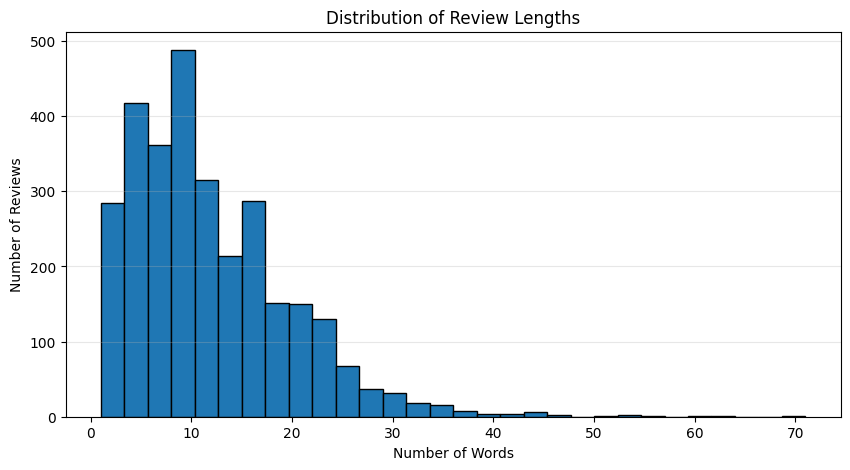


Shortest reviews:


,text,word_count,label,source
185,Incredible!.,1,1,Amazon
463,Disappointed!.,1,0,Amazon
751,disappointing.,1,0,Amazon
777,WORTHWHILE.,1,1,Amazon
877,Excellent!.,1,1,Amazon



Longest reviews:


,text,word_count,label,source
1620,"This is a masterful piece of film-making, with...",71,1,IMDb
1421,This movie is excellent!Angel is beautiful and...,62,1,IMDb
1298,I have to mention this and it is a huge SPOILE...,61,1,IMDb
1428,The use of slow-motion needlessly repeats itse...,56,0,IMDb
1390,Though The Wind and the Lion is told largely t...,54,1,IMDb


In [10]:

# Purpose: Calculate review lengths and explore the
# distribution of word counts across the dataset.
# This is descriptive exploration only. Final length
# boundaries will be determined after the train/dev/test split.

# Count words using whitespace-separated tokens.
df["word_count"] = df["text"].str.split().str.len()

print("========== REVIEW LENGTH STATISTICS ==========")

print("\nOverall word count statistics:")
display(df["word_count"].describe())

print("\nWord count percentiles:")
display(
    df["word_count"].quantile(
        [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nWord count by source:")
display(
    df.groupby("source")["word_count"].agg(
        ["count", "min", "median", "mean", "max"]
    ).round(2)
)

print("\nWord count by sentiment label:")
display(
    df.groupby("label")["word_count"].agg(
        ["count", "min", "median", "mean", "max"]
    ).round(2)
)

# Visualize the distribution.
plt.figure(figsize=(10, 5))

plt.hist(
    df["word_count"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)

plt.show()

print("\nShortest reviews:")
display(
    df.nsmallest(5, "word_count")
    [["text", "word_count", "label", "source"]]
)

print("\nLongest reviews:")
display(
    df.nlargest(5, "word_count")
    [["text", "word_count", "label", "source"]]
)


8. Prepare Groups for Leakage-Free Splitting

In [11]:

# Purpose: Assign identical cleaned reviews to the same
# group so duplicates cannot cross training, development,
# and testing boundaries.

import hashlib

# Create a stable identifier for each unique review text.
def create_text_group(text):
    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()

df["text_group"] = df["text"].apply(create_text_group)

print("Total reviews:", len(df))
print("Unique text groups:", df["text_group"].nunique())

# Verify that each group has one sentiment label.
conflicting_groups = (
    df.groupby("text_group")["label"].nunique() > 1
).sum()

print("Groups with conflicting labels:", conflicting_groups)

assert conflicting_groups == 0, (
    "Identical reviews have conflicting sentiment labels!"
)

print("\nDuplicate-safe groups created successfully.")


Total reviews: 3000
Unique text groups: 2982
Groups with conflicting labels: 0

Duplicate-safe groups created successfully.


9. Create Stratified Train, Development, and Test Sets

In [12]:

# Purpose: Split the data into approximately 70% training,
# 15% development, and 15% testing while keeping identical
# reviews together and preserving label/source proportions.

from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Work with one row per unique text group.
group_table = (
    df.groupby("text_group", as_index=False)
      .agg(
          label=("label", "first"),
          source=("source", "first")
      )
)

# Stratify using both sentiment label and source.
group_table["stratum"] = (
    group_table["source"]
    + "_"
    + group_table["label"].astype(str)
)

# First split: 70% train, 30% temporary.
train_groups, temp_groups = train_test_split(
    group_table,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=group_table["stratum"]
)

# Second split: divide temporary groups equally.
dev_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temp_groups["stratum"]
)

# Assign each original row to its corresponding split.
train_df = df[
    df["text_group"].isin(train_groups["text_group"])
].copy()

dev_df = df[
    df["text_group"].isin(dev_groups["text_group"])
].copy()

test_df = df[
    df["text_group"].isin(test_groups["text_group"])
].copy()

# Reset indices for clean output.
train_df = train_df.reset_index(drop=True)
dev_df = dev_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("========== DATASET SPLITS ==========")

print(f"Training:    {len(train_df)} reviews")
print(f"Development: {len(dev_df)} reviews")
print(f"Testing:     {len(test_df)} reviews")

print("\nTotal:", len(train_df) + len(dev_df) + len(test_df))

print("\nSplit percentages:")
for name, split in [
    ("Train", train_df),
    ("Dev", dev_df),
    ("Test", test_df)
]:
    print(f"{name}: {len(split)/len(df)*100:.2f}%")


========== DATASET SPLITS ==========
Training:    2099 reviews
Development: 449 reviews
Testing:     452 reviews

Total: 3000

Split percentages:
Train: 69.97%
Dev: 14.97%
Test: 15.07%


10. Validate Data Splits and Check for Leakage

In [13]:

# Purpose: Verify that data splits preserve the dataset,
# contain no duplicate leakage, and maintain reasonable
# sentiment and source distributions.

print("========== SPLIT VALIDATION ==========")

# Confirm all original rows are included.
assert (
    len(train_df) + len(dev_df) + len(test_df)
    == len(df)
)

print("All original reviews accounted for: PASS")

# Check whether text groups overlap.
train_ids = set(train_df["text_group"])
dev_ids = set(dev_df["text_group"])
test_ids = set(test_df["text_group"])

assert train_ids.isdisjoint(dev_ids)
assert train_ids.isdisjoint(test_ids)
assert dev_ids.isdisjoint(test_ids)

print("No duplicate text leakage: PASS")

# Check sentiment and source distributions.
for name, split in [
    ("Training", train_df),
    ("Development", dev_df),
    ("Testing", test_df)
]:
    print(f"\n========== {name.upper()} ==========")

    print("Total reviews:", len(split))

    print("\nLabel distribution:")
    print(split["label"].value_counts().sort_index())

    print("\nSource × Label:")
    display(
        pd.crosstab(split["source"], split["label"])
    )

    print("\nWord count statistics:")
    print(split["word_count"].describe().round(2))

print("\nAll split validations completed.")


========== SPLIT VALIDATION ==========
All original reviews accounted for: PASS
No duplicate text leakage: PASS

========== TRAINING ==========
Total reviews: 2099

Label distribution:
label
0    1053
1    1046
Name: count, dtype: int64

Source × Label:


label,0,1
source,,
Amazon,351,348
IMDb,351,348
Yelp,351,350



Word count statistics:
count    2099.00
mean       11.84
std         7.88
min         1.00
25%         6.00
50%        10.00
75%        16.00
max        71.00
Name: word_count, dtype: float64

========== DEVELOPMENT ==========
Total reviews: 449

Label distribution:
label
0    223
1    226
Name: count, dtype: int64

Source × Label:


label,0,1
source,,
Amazon,74,75
IMDb,75,76
Yelp,74,75



Word count statistics:
count    449.00
mean      11.72
std        7.80
min        1.00
25%        5.00
50%       10.00
75%       16.00
max       45.00
Name: word_count, dtype: float64

========== TESTING ==========
Total reviews: 452

Label distribution:
label
0    224
1    228
Name: count, dtype: int64

Source × Label:


label,0,1
source,,
Amazon,75,77
IMDb,74,76
Yelp,75,75



Word count statistics:
count    452.00
mean      11.90
std        7.92
min        1.00
25%        5.00
50%       10.00
75%       17.00
max       51.00
Name: word_count, dtype: float64

All split validations completed.


11. Define Review Length Categories Using Training Data

In [14]:

# Purpose: Determine short, medium, and long review
# boundaries using ONLY the training dataset.
# This prevents the held-out test set from influencing
# our experimental design.

# Calculate the 33rd and 67th percentiles.
lower_threshold = int(
    train_df["word_count"].quantile(1/3)
)

upper_threshold = int(
    train_df["word_count"].quantile(2/3)
)

# Verify that the thresholds are different.
assert lower_threshold < upper_threshold, (
    "Length thresholds overlap. Review grouping is needed."
)

print("========== TRAINING-BASED THRESHOLDS ==========")

print("Short: 1 to", lower_threshold, "words")
print(
    "Medium:",
    lower_threshold + 1,
    "to",
    upper_threshold,
    "words"
)
print("Long:", upper_threshold + 1, "words or more")

print("\nTraining word-count statistics:")
display(train_df["word_count"].describe())


========== TRAINING-BASED THRESHOLDS ==========
Short: 1 to 7 words
Medium: 8 to 14 words
Long: 15 words or more

Training word-count statistics:


,word_count
count,2099.000000
mean,11.838971
std,7.881619
min,1.000000
25%,6.000000
50%,10.000000
75%,16.000000
max,71.000000


12. Assign Length Categories to Train, Dev, and Test

In [15]:

# Purpose: Categorize reviews into short, medium,
# and long using the SAME training-derived boundaries
# across all datasets.

def assign_length_group(word_count):

    if word_count <= lower_threshold:
        return "Short"

    elif word_count <= upper_threshold:
        return "Medium"

    else:
        return "Long"


# Apply categories to all three splits.
for split in [train_df, dev_df, test_df]:

    split["length_group"] = (
        split["word_count"].apply(assign_length_group)
    )

print("========== LENGTH GROUP DISTRIBUTION ==========")

for name, split in [
    ("Training", train_df),
    ("Development", dev_df),
    ("Testing", test_df)
]:
    print(f"\n{name}:")

    print(
        split["length_group"]
        .value_counts()
        .reindex(["Short", "Medium", "Long"])
    )

print("\nExample reviews from each group:")

for group in ["Short", "Medium", "Long"]:

    print(f"\n========== {group.upper()} ==========")

    display(
        train_df[
            train_df["length_group"] == group
        ][["text", "word_count", "label", "source"]]
        .head(3)
    )


========== LENGTH GROUP DISTRIBUTION ==========

Training:
length_group
Short     731
Medium    734
Long      634
Name: count, dtype: int64

Development:
length_group
Short     172
Medium    137
Long      140
Name: count, dtype: int64

Testing:
length_group
Short     160
Medium    146
Long      146
Name: count, dtype: int64

Example reviews from each group:

========== SHORT ==========


,text,word_count,label,source
1,"Good case, Excellent value.",4,1,Amazon
2,The mic is great.,4,1,Amazon
4,"Needless to say, I wasted my money.",7,0,Amazon



========== MEDIUM ==========


,text,word_count,label,source
6,He was very impressed when going from the orig...,14,1,Amazon
8,Highly recommend for any one who has a blue to...,11,1,Amazon
13,I bought this to use with my Kindle Fire and a...,13,1,Amazon



========== LONG ==========


,text,word_count,label,source
0,So there is no way for me to plug it in here i...,21,0,Amazon
3,I have to jiggle the plug to get it to line up...,17,0,Amazon
7,"The design is very odd, as the ear ""clip"" is n...",15,0,Amazon


13. Validate Length Categories and Class Balance

In [16]:

# Purpose: Verify that every review belongs to one
# length group, inspect class balance, and identify
# possible source-related differences in length.

GROUP_ORDER = ["Short", "Medium", "Long"]

for name, split in [
    ("Training", train_df),
    ("Development", dev_df),
    ("Testing", test_df)
]:

    print(f"\n========== {name.upper()} ==========")

    # Check that every review has a valid category.
    assert split["length_group"].notna().all()
    assert split["length_group"].isin(GROUP_ORDER).all()

    # Count positive and negative reviews per group.
    print("\nLength group × Sentiment:")

    length_label_table = pd.crosstab(
        split["length_group"],
        split["label"]
    ).reindex(GROUP_ORDER, fill_value=0)

    display(length_label_table)

    # Examine source composition.
    print("\nLength group × Source:")

    length_source_table = pd.crosstab(
        split["length_group"],
        split["source"]
    ).reindex(GROUP_ORDER, fill_value=0)

    display(length_source_table)

    # Summarize word counts.
    print("\nWord count by length group:")

    display(
        split.groupby("length_group")["word_count"]
        .agg(["count", "min", "median", "mean", "max"])
        .reindex(GROUP_ORDER)
        .round(2)
    )

print("\nAll length-category validation checks passed!")



========== TRAINING ==========

Length group × Sentiment:


label,0,1
length_group,,
Short,355,376
Medium,367,367
Long,331,303



Length group × Source:


source,Amazon,IMDb,Yelp
length_group,,,
Short,305,168,258
Medium,216,245,273
Long,178,286,170



Word count by length group:


,count,min,median,mean,max
length_group,,,,,
Short,731,1,5.0,4.69,7
Medium,734,8,11.0,10.71,14
Long,634,15,20.0,21.39,71


... (9 outputs left out)

source,Amazon,IMDb,Yelp
length_group,,,
Short,69,48,43
Medium,38,50,58
Long,45,52,49



Word count by length group:


,count,min,median,mean,max
length_group,,,,,
Short,160,1,5.0,4.51,7
Medium,146,8,11.0,10.66,14
Long,146,15,20.0,21.26,51



All length-category validation checks passed!


14. Final Data Integrity and Quality Checks

In [17]:

# Purpose: Verify dataset integrity, split independence,
# sentiment labels, and review-length categories before export.

import pandas as pd

splits = {
    "train": train_df,
    "dev": dev_df,
    "test": test_df
}

GROUP_ORDER = ["Short", "Medium", "Long"]

# Confirm the total number of records.
assert sum(len(s) for s in splits.values()) == 3000

# Confirm valid sentiment labels and length categories.
for name, split in splits.items():
    assert split["text"].notna().all()
    assert split["text"].str.strip().ne("").all()
    assert split["label"].isin([0, 1]).all()
    assert split["length_group"].isin(GROUP_ORDER).all()
    assert (
        split["word_count"]
        == split["text"].str.split().str.len()
    ).all()

# Confirm that identical texts do not cross splits.
for name_a, name_b in [
    ("train", "dev"),
    ("train", "test"),
    ("dev", "test")
]:
    overlap = set(splits[name_a]["text"]) & set(
        splits[name_b]["text"]
    )
    assert len(overlap) == 0, (
        f"Data leakage detected: {name_a} vs {name_b}"
    )

# Confirm boundaries were applied consistently.
for name, split in splits.items():
    expected = split["word_count"].apply(
        lambda n: "Short" if n <= lower_threshold
        else "Medium" if n <= upper_threshold
        else "Long"
    )
    assert (split["length_group"] == expected).all()

print("FINAL VALIDATION RESULTS")
print("-" * 45)
print("Dataset completeness: PASS")
print("Missing or empty text: PASS")
print("Sentiment labels: PASS")
print("Word-count calculations: PASS")
print("Length categories: PASS")
print("Duplicate leakage: PASS")
print("\nAll final data checks passed!")


FINAL VALIDATION RESULTS
---------------------------------------------
Dataset completeness: PASS
Missing or empty text: PASS
Sentiment labels: PASS
Word-count calculations: PASS
Length categories: PASS
Duplicate leakage: PASS

All final data checks passed!


15. Export Prepared Datasets as CSV Files

In [18]:

# Purpose: Export standardized CSV files that all
# team members can use for model training and evaluation.

from pathlib import Path

OUTPUT_DIR = Path("Group10_Prepared_Data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPORT_COLUMNS = [
    "text",
    "label",
    "source",
    "word_count",
    "length_group",
    "text_group"
]

for name, split in splits.items():

    output_file = OUTPUT_DIR / f"{name}.csv"

    split[EXPORT_COLUMNS].to_csv(
        output_file,
        index=False,
        encoding="utf-8"
    )

    print(
        f"Saved {output_file.name}: "
        f"{len(split)} reviews"
    )

print("\nAll three datasets exported successfully!")


Saved train.csv: 2099 reviews
Saved dev.csv: 449 reviews
Saved test.csv: 452 reviews

All three datasets exported successfully!


16. Save Dataset Summary and Experimental Configuration

In [19]:

# Purpose: Create a JSON summary documenting the dataset,
# splitting method, review-length boundaries, and statistics.

import json

summary = {
    "project": "Group 10 - Review Length Sentiment Analysis",
    "dataset": "UCI Sentiment Labelled Sentences",
    "dataset_url": (
        "https://archive.ics.uci.edu/dataset/331/"
        "sentiment+labelled+sentences"
    ),
    "random_seed": RANDOM_SEED,
    "total_reviews": len(df),
    "unique_texts": int(df["text_group"].nunique()),
    "preprocessing": [
        "Normalize whitespace",
        "Remove empty reviews",
        "Preserve punctuation and negation",
        "Keep identical review texts within the same split"
    ],
    "splitting_method": (
        "Stratified train/dev/test splitting by source and "
        "sentiment at unique-text-group level"
    ),
    "length_definition": "Whitespace-separated word count",
    "length_thresholds": {
        "Short": f"1-{lower_threshold} words",
        "Medium": (
            f"{lower_threshold + 1}-{upper_threshold} words"
        ),
        "Long": f"{upper_threshold + 1}+ words"
    },
    "splits": {}
}

for name, split in splits.items():

    summary["splits"][name] = {
        "total": len(split),
        "labels": {
            str(k): int(v)
            for k, v in split["label"].value_counts().items()
        },
        "length_groups": {
            group: int((split["length_group"] == group).sum())
            for group in GROUP_ORDER
        },
        "sources": {
            str(k): int(v)
            for k, v in split["source"].value_counts().items()
        }
    }

summary_path = OUTPUT_DIR / "data_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("Dataset summary saved successfully!")
print("\nExperimental configuration:")
print(json.dumps(summary["length_thresholds"], indent=4))

print("\nSplit sizes:")
for name in splits:
    print(name, summary["splits"][name]["total"])


Dataset summary saved successfully!

Experimental configuration:
{
    "Short": "1-7 words",
    "Medium": "8-14 words",
    "Long": "15+ words"
}

Split sizes:
train 2099
dev 449
test 452


17. Package and Download Data Preparation Deliverables

In [20]:

# Purpose: Package the prepared CSV files and summary
# into one ZIP file for sharing with the project team.

import zipfile

zip_path = Path("Group10_Data_Handoff.zip")

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file in sorted(OUTPUT_DIR.iterdir()):
        if file.is_file():
            archive.write(
                file,
                arcname=file.name
            )

print("ZIP package created:", zip_path)

with zipfile.ZipFile(zip_path) as archive:
    print("\nFiles included:")
    for filename in archive.namelist():
        print("-", filename)

# Automatically download the ZIP in Google Colab.
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("\nDownload manually if not using Google Colab.")


ZIP package created: Group10_Data_Handoff.zip

Files included:
- data_summary.json
- dev.csv
- test.csv
- train.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Part B — Method 1: TF-IDF + Logistic Regression

This section implements the traditional sentiment classification method using TF-IDF word unigrams and bigrams with Logistic Regression. Hyperparameters are selected using the development set before evaluating the model on the held-out test set.

18.Load the CSVs and tunes hyperparameters on dev

In [21]:
import joblib
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
OUT = Path("Method1_outputs")
OUT.mkdir(exist_ok=True)

# CSVs in the notebook's folder
folder = Path(".") if Path("train.csv").exists() else Path("Group10_Prepared_Data")

train = pd.read_csv(folder / "train.csv")   # used to train
dev   = pd.read_csv(folder / "dev.csv")     # used to tune
test  = pd.read_csv(folder / "test.csv")    # used once at the end

test["row_id"] = range(len(test))           # original row position
print(len(train), len(dev), len(test))

def make_model(C, min_df, sublinear_tf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=min_df, sublinear_tf=sublinear_tf)),
        ("logreg", LogisticRegression(C=C, max_iter=1000, random_state=SEED)),
    ])

results = []
for C in [0.1, 0.5, 1, 2, 5, 10, 20, 50, 100]:
    for min_df in [1, 2]:
        for sublinear_tf in [False, True]:
            model = make_model(C, min_df, sublinear_tf)
            model.fit(train["text"], train["label"])          # train on TRAIN
            pred = model.predict(dev["text"])                 # score on DEV
            results.append([C, min_df, sublinear_tf,
                            accuracy_score(dev["label"], pred),
                            f1_score(dev["label"], pred, average="macro")])

tuning = pd.DataFrame(results, columns=["C", "min_df", "sublinear_tf", "dev_acc", "dev_macro_f1"])
tuning = tuning.sort_values(["dev_macro_f1", "dev_acc", "C"], ascending=[False, False, True])
tuning = tuning.reset_index(drop=True)
tuning.to_csv(OUT / "tuning_results_dev.csv", index=False)
display(tuning.head(5).round(4))

best = tuning.iloc[0]
print("Best settings: C =", best["C"], "| min_df =", int(best["min_df"]), "| sublinear_tf =", bool(best["sublinear_tf"]))

2099 449 452


,C,min_df,sublinear_tf,dev_acc,dev_macro_f1
0,50.0,1,True,0.8396,0.8396
1,100.0,1,True,0.8396,0.8396
2,20.0,1,True,0.8396,0.8395
3,50.0,1,False,0.8396,0.8395
4,100.0,1,False,0.8352,0.8351


Best settings: C = 50.0 | min_df = 1 | sublinear_tf = True


19.Train the final model on train, evaluates on test once, and writes the predictions CSV

In [22]:
final_model = make_model(best["C"], int(best["min_df"]), bool(best["sublinear_tf"]))
final_model.fit(train["text"], train["label"])
joblib.dump(final_model, OUT / "tfidf_logreg_pipeline.joblib")

predicted = final_model.predict(test["text"])

# Overall + per length group
rows = []
for group in ["Short", "Medium", "Long", "Overall"]:
    keep = (test["length_group"] == group) if group != "Overall" else (test["length_group"] != "")
    acc = accuracy_score(test["label"][keep], predicted[keep])
    f1 = f1_score(test["label"][keep], predicted[keep], average="macro")
    rows.append([group, keep.sum(), acc, f1])
scores = pd.DataFrame(rows, columns=["length_group", "n", "accuracy", "macro_f1"])
display(scores.round(4))
scores.to_csv(OUT / "test_results_by_length.csv", index=False)

# Prediction file (same order as test.csv)
out = test[["row_id", "text", "label", "length_group"]].copy()
out = out.rename(columns={"label": "true_label"})
out["predicted_label"] = predicted
out = out[["row_id", "text", "true_label", "predicted_label", "length_group"]]
out.to_csv(OUT / "method1_tfidf_lr_test_predictions.csv", index=False)


,length_group,n,accuracy,macro_f1
0,Short,160,0.8312,0.8304
1,Medium,146,0.8699,0.8697
2,Long,146,0.6986,0.6981
3,Overall,452,0.8009,0.8008


### Interactive Prediction Using Method 1

In [23]:
def predict_sentiment(text):
    prob = final_model.predict_proba([text])[0][1]      # probability of Positive
    return ("Positive" if prob >= 0.5 else "Negative"), float(prob)

print(predict_sentiment("This is not good at all."))

('Negative', 0.03651193591099866)


### Export Method 1 Prediction Probabilities
This step exports the positive-class prediction probabilities from the trained TF-IDF + Logistic Regression model.

The probabilities are saved in `method1_probabilities.csv` and used for comparative evaluation and error analysis. This process does not involve retraining or modifying the model.

In [24]:
# Export positive-class prediction probabilities from the trained TF-IDF model for comparative evaluation.
method1_probs = pd.DataFrame({
    "row_id": test["row_id"].to_numpy(),
    "prob_positive": final_model.predict_proba(test["text"])[:, list(final_model.classes_).index(1)],
})
method1_probs.to_csv(OUT / "method1_probabilities.csv", index=False)
print("Saved", OUT / "method1_probabilities.csv")

Saved Method1_outputs/method1_probabilities.csv


## Part C - Method 2: Sentence-BERT + Logistic Regression
This section implements the pretrained sentiment classification method using Sentence-BERT (all-MiniLM-L6-v2) embeddings with Logistic Regression. The pretrained encoder generates sentence representations, while the classifier is trained and tuned using the prepared data.



**Model:** `sentence-transformers/all-MiniLM-L6-v2`  
**Output folder:** `Method2_outputs/`  
**Label mapping:** 0 = Negative, 1 = Positive.

### 18. Install and import libraries for Method 2

In [25]:
%pip -q install sentence-transformers joblib scikit-learn pandas numpy

In [26]:

import json
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
from IPython.display import display
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

M2_SEED = 42
M2_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
M2_OUT = Path("Method2_outputs")
M2_OUT.mkdir(parents=True, exist_ok=True)
print("Method 2 dependencies ready.")

Method 2 dependencies ready.


### 19.Dataset Loading and Validation




In [27]:

M2_DATA_DIR = Path("Group10_Prepared_Data") if Path("Group10_Prepared_Data/train.csv").exists() else Path(".")
if not (M2_DATA_DIR / "train.csv").exists():
    handoff = next(iter(sorted(Path(".").glob("*Data_Handoff*.zip"))), None)
    if handoff is not None:
        M2_DATA_DIR = Path("Group10_M2_Handoff_Extracted")
        M2_DATA_DIR.mkdir(exist_ok=True)
        with zipfile.ZipFile(handoff) as zf:
            zf.extractall(M2_DATA_DIR)
    else:
        raise FileNotFoundError("Prepared datasets not found. Run the Data Preparation section first or upload Group10_Data_Handoff.zip.")

m2_train = pd.read_csv(M2_DATA_DIR / "train.csv")
m2_dev = pd.read_csv(M2_DATA_DIR / "dev.csv")
m2_test = pd.read_csv(M2_DATA_DIR / "test.csv")
required = {"text", "label", "length_group"}
for split_name, split in [("train", m2_train), ("dev", m2_dev), ("test", m2_test)]:
    assert required.issubset(split.columns), f"Missing columns in {split_name}: {required-set(split.columns)}"
    assert split["text"].notna().all(), f"Blank text in {split_name}"
    assert set(split["label"].unique()) <= {0, 1}, f"Unexpected labels in {split_name}"
    assert set(split["length_group"].unique()) <= {"Short", "Medium", "Long"}, f"Unexpected length groups in {split_name}"
    print(f"{split_name}: {len(split)} examples; length groups: {split['length_group'].value_counts().to_dict()}")

assert len(m2_train) == 2099 and len(m2_dev) == 449 and len(m2_test) == 452, "Check the team handoff data; splits differ from approved files."
assert set(m2_train["text_group"]).isdisjoint(set(m2_dev["text_group"]))
assert set(m2_train["text_group"]).isdisjoint(set(m2_test["text_group"]))
assert set(m2_dev["text_group"]).isdisjoint(set(m2_test["text_group"]))
# Preserve row identifiers consistent with the common test-set order.
m2_test = m2_test.copy()
m2_test["row_id"] = np.arange(len(m2_test))
print("Prepared splits verified. No resplitting performed.")

train: 2099 examples; length groups: {'Medium': 734, 'Short': 731, 'Long': 634}
dev: 449 examples; length groups: {'Short': 172, 'Long': 140, 'Medium': 137}
test: 452 examples; length groups: {'Short': 160, 'Long': 146, 'Medium': 146}
Prepared splits verified. No resplitting performed.


### 20. Sentence Embedding Extraction



In [28]:
m2_encoder = SentenceTransformer(M2_MODEL_NAME)

# Embeddings are generated once and reused across the tuning grid.
m2_x_train = m2_encoder.encode(m2_train["text"].tolist(), batch_size=32, show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True)
m2_x_dev = m2_encoder.encode(m2_dev["text"].tolist(), batch_size=32, show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True)
print("Train embeddings:", m2_x_train.shape)
print("Dev embeddings:", m2_x_dev.shape)
print("Pretrained encoder is used for feature extraction only.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/66 [00:00<?, ?it/s]

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

Train embeddings: (2099, 384)
Dev embeddings: (449, 384)
Pretrained encoder is used for feature extraction only.


### 21. Logistic Regression Training and Hyperparameter Tuning


In [29]:
m2_c_values = [0.1, 0.5, 1, 2, 5, 10, 20, 50, 100]
m2_trials = []
for c_value in m2_c_values:
    clf = LogisticRegression(C=c_value, max_iter=2000, random_state=M2_SEED)
    clf.fit(m2_x_train, m2_train["label"])
    dev_pred = clf.predict(m2_x_dev)
    m2_trials.append({
        "C": c_value,
        "dev_acc": accuracy_score(m2_dev["label"], dev_pred),
        "dev_macro_f1": f1_score(m2_dev["label"], dev_pred, average="macro", zero_division=0),
    })

m2_tuning = pd.DataFrame(m2_trials).sort_values(
    ["dev_macro_f1", "dev_acc", "C"], ascending=[False, False, True]
).reset_index(drop=True)
m2_tuning.to_csv(M2_OUT / "tuning_results_dev.csv", index=False)
display(m2_tuning.round(4))
m2_best_c = float(m2_tuning.iloc[0]["C"])
print("Selected C =", m2_best_c, "from development data only.")

,C,dev_acc,dev_macro_f1
0,2.0,0.9087,0.9087
1,1.0,0.9065,0.9064
2,5.0,0.9020,0.9020
3,0.5,0.8998,0.8998
4,10.0,0.8998,0.8997
5,0.1,0.8976,0.8975
6,20.0,0.8864,0.8864
7,50.0,0.8820,0.8820
8,100.0,0.8552,0.8552


Selected C = 2.0 from development data only.


### 22. Model Evaluation — Accuracy and Macro F1

The selected classifier is trained using the training set only, with hyperparameters chosen based on development-set performance. The held-out test set is reserved for final evaluation.

Both methods are evaluated on identical test examples to ensure a fair comparison.

In [30]:
m2_classifier = LogisticRegression(C=m2_best_c, max_iter=2000, random_state=M2_SEED)
m2_classifier.fit(m2_x_train, m2_train["label"])

# Test embeddings are generated only after the development-set selection.
m2_x_test = m2_encoder.encode(m2_test["text"].tolist(), batch_size=32, show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True)
m2_test_pred = m2_classifier.predict(m2_x_test)
m2_test_prob = m2_classifier.predict_proba(m2_x_test)[:, list(m2_classifier.classes_).index(1)]

m2_score_rows = []
for length_group in ["Short", "Medium", "Long", "Overall"]:
    mask = (m2_test["length_group"] == length_group).to_numpy() if length_group != "Overall" else np.ones(len(m2_test), dtype=bool)
    if mask.sum() == 0:
        continue
    y_true = m2_test.loc[mask, "label"].to_numpy()
    y_pred = m2_test_pred[mask]
    m2_score_rows.append({
        "length_group": length_group,
        "n": int(mask.sum()),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    })
m2_scores = pd.DataFrame(m2_score_rows)
display(m2_scores.round(4))
m2_scores.to_csv(M2_OUT / "test_results_by_length.csv", index=False)
print("Classification report (overall):")
print(classification_report(m2_test["label"], m2_test_pred, target_names=["Negative", "Positive"], zero_division=0))
print("Confusion matrix (labels 0/1):")
print(confusion_matrix(m2_test["label"], m2_test_pred, labels=[0, 1]))

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

,length_group,n,accuracy,macro_f1
0,Short,160,0.9312,0.9312
1,Medium,146,0.8425,0.8425
2,Long,146,0.8836,0.8834
3,Overall,452,0.8872,0.8871


Classification report (overall):
              precision    recall  f1-score   support

    Negative       0.87      0.91      0.89       224
    Positive       0.91      0.86      0.89       228

    accuracy                           0.89       452
   macro avg       0.89      0.89      0.89       452
weighted avg       0.89      0.89      0.89       452

Confusion matrix (labels 0/1):
[[204  20]
 [ 31 197]]


### 23.Test Predictions and Results Export



In [31]:
m2_predictions = m2_test[["row_id", "text", "label", "length_group"]].rename(columns={"label": "true_label"}).copy()
m2_predictions["predicted_label"] = m2_test_pred
m2_predictions = m2_predictions[["row_id", "text", "true_label", "predicted_label", "length_group"]]
m2_predictions.to_csv(M2_OUT / "method2_sbert_lr_test_predictions.csv", index=False)

# Optional confidence file (kept separate to preserve the required comparison schema)
m2_confidence = m2_predictions[["row_id"]].copy()
m2_confidence["prob_positive"] = m2_test_prob
m2_confidence.to_csv(M2_OUT / "method2_probabilities.csv", index=False)

assert len(m2_predictions) == len(m2_test)
assert (m2_predictions["row_id"].to_numpy() == np.arange(len(m2_test))).all()
assert (m2_predictions["text"].to_numpy() == m2_test["text"].to_numpy()).all()
display(m2_predictions.head())
print("Predictions saved .")

,row_id,text,true_label,predicted_label,length_group
0,0,Great for the jawbone.,1,1,Short
1,1,This case seems well made.,1,1,Short
2,2,VERY DISAPPOINTED.,0,0,Short
3,3,I have been very happy with the 510 and have h...,1,1,Long
4,4,Essentially you can forget Microsoft's tech su...,0,0,Short


Predictions saved .


### 24. Model Saving and Configuration



In [32]:
joblib.dump(m2_classifier, M2_OUT / "sbert_logreg_classifier.joblib")
m2_config = {
    "method": "Frozen Sentence-BERT embeddings + Logistic Regression",
    "pretrained_model": M2_MODEL_NAME,
    "normalize_embeddings": True,
    "label_mapping": {"0": "Negative", "1": "Positive"},
    "random_seed": M2_SEED,
    "selected_C": m2_best_c,
    "tuning_metric": "development macro F1, development accuracy tiebreak",
    "training_examples": len(m2_train),
    "development_examples": len(m2_dev),
    "test_examples": len(m2_test),
    "data_source": "Prepared stratified train/development/test datasets",
}
with open(M2_OUT / "method2_config.json", "w", encoding="utf-8") as f:
    json.dump(m2_config, f, indent=2)

m2_zip_path = Path("Group10_M3_SentenceBERT_Outputs.zip")
with zipfile.ZipFile(m2_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(M2_OUT.iterdir()):
        if path.is_file():
            zf.write(path, arcname=path.name)
print("Saved:", m2_zip_path)
print("Output files:", sorted(p.name for p in M2_OUT.iterdir()))
try:
    from google.colab import files
    files.download(str(m2_zip_path))
except ImportError:
    print("Download the ZIP manually if not running on Colab.")

Saved: Group10_M3_SentenceBERT_Outputs.zip
Output files: ['method2_config.json', 'method2_probabilities.csv', 'method2_sbert_lr_test_predictions.csv', 'sbert_logreg_classifier.joblib', 'test_results_by_length.csv', 'tuning_results_dev.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 25. Sentiment Prediction — Try It

In [33]:
def predict_sentiment_sbert(text):
    if not isinstance(text, str) or not text.strip():
        return "Please enter a non-empty English review."
    features = m2_encoder.encode([text.strip()], convert_to_numpy=True, normalize_embeddings=True)
    probability_positive = float(m2_classifier.predict_proba(features)[0, list(m2_classifier.classes_).index(1)])
    predicted_label = "Positive" if probability_positive >= 0.5 else "Negative"
    return {"review": text, "prediction": predicted_label, "prob_positive": round(probability_positive, 4)}

print(predict_sentiment_sbert("The food was delicious and the service was wonderful."))
print(predict_sentiment_sbert("The food was terrible."))
print(predict_sentiment_sbert(""))

{'review': 'The food was delicious and the service was wonderful.', 'prediction': 'Positive', 'prob_positive': 0.9935}
{'review': 'The food was terrible.', 'prediction': 'Negative', 'prob_positive': 0.0008}
Please enter a non-empty English review.


## Part D - Evaluation, Analysis, and Interactive Prediction
This section compares the performance of TF-IDF + Logistic Regression and Sentence-BERT + Logistic Regression on the same held-out test set.

We evaluate both methods using Accuracy and Macro F1 across Short, Medium, and Long reviews. We also analyze performance consistency, examine classification errors, and provide an interactive prediction feature for new reviews.

## 1. Evaluation protocol
- Short = 1-7 words, Medium = 8-14 words, Long = 15+ words.
- Length boundaries were derived from the training set and remain fixed.
- Both models are evaluated on the same 452 test reviews.
- Primary metrics: **Accuracy** and **Macro F1**.
- For the research question, **consistency** is operationalized as the range between the highest and lowest Macro F1 across Short, Medium, and Long groups. A smaller range means more stable performance across review lengths.

In [34]:
# Configure paths for the prepared datasets, model outputs, and evaluation results.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

BASE = Path('.')
DATA_DIR = BASE / 'Group10_Prepared_Data'  # Prepared dataset directory
M1_DIR = BASE / 'Method1_outputs'           # Traditional model output directory
M2_DIR = BASE / 'Method2_outputs'           # Pretrained model output directory
OUT_DIR = BASE / 'evaluation_outputs'       # Evaluation results directory
FIG_DIR = BASE / 'figures'                  # Visualization output directory
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',120)
print("Evaluation environment initialized successfully.")

Evaluation environment initialized successfully.


## 2. Load the common test set and both prediction files

In [35]:
# Load the common test set and prediction files generated by both classification methods.
# Verify that both models' predictions match the original test-set rows and labels.
test_eval = pd.read_csv(DATA_DIR / 'test.csv').reset_index().rename(columns={'index':'row_id', 'label':'true_label'})
m1 = pd.read_csv(M1_DIR / 'method1_tfidf_lr_test_predictions.csv')
m2 = pd.read_csv(M2_DIR / 'method2_sbert_lr_test_predictions.csv')
p1 = pd.read_csv(M1_DIR / 'method1_probabilities.csv')
p2 = pd.read_csv(M2_DIR / 'method2_probabilities.csv')

assert len(test_eval) == len(m1) == len(m2) == 452
assert m1['row_id'].tolist() == test_eval['row_id'].tolist() == m2['row_id'].tolist()
assert (m1['text'].values == test_eval['text'].values).all()
assert (m2['text'].values == test_eval['text'].values).all()
assert (m1['true_label'].values == test_eval['true_label'].values).all()
assert (m2['true_label'].values == test_eval['true_label'].values).all()
assert (m1['length_group'].values == test_eval['length_group'].values).all()
assert (m2['length_group'].values == test_eval['length_group'].values).all()
assert p1['row_id'].tolist() == test_eval['row_id'].tolist() == p2['row_id'].tolist()

combined = test_eval[['row_id','text','true_label','source','word_count','length_group']].copy()
combined['tfidf_prediction'] = m1['predicted_label'].values
combined['sbert_prediction'] = m2['predicted_label'].values
combined['tfidf_prob_positive'] = p1['prob_positive'].values
combined['sbert_prob_positive'] = p2['prob_positive'].values
combined['tfidf_correct'] = combined['tfidf_prediction'].eq(combined['true_label'])
combined['sbert_correct'] = combined['sbert_prediction'].eq(combined['true_label'])
combined.to_csv(OUT_DIR / 'combined_test_predictions.csv', index=False)
print('Alignment checks passed. Both models use the same 452 held-out reviews.')
display(combined.head())

Alignment checks passed. Both models use the same 452 held-out reviews.


,row_id,text,true_label,source,word_count,length_group,tfidf_prediction,sbert_prediction,tfidf_prob_positive,sbert_prob_positive,tfidf_correct,sbert_correct
0,0,Great for the jawbone.,1,Amazon,4,Short,1,1,0.999637,0.927834,True,True
1,1,This case seems well made.,1,Amazon,5,Short,1,1,0.926528,0.954601,True,True
2,2,VERY DISAPPOINTED.,0,Amazon,2,Short,0,0,0.019890,0.047206,True,True
3,3,I have been very happy with the 510 and have had NO complaints from any one regarding my sound quality on their end.,1,Amazon,23,Long,1,1,0.968990,0.799751,True,True
4,4,Essentially you can forget Microsoft's tech support.,0,Amazon,7,Short,1,0,0.505823,0.216396,False,True


## 3. Overall and length-group evaluation

In [36]:
rows = []
for model_name, pred_col in [('TF-IDF + LR','tfidf_prediction'), ('SBERT + LR','sbert_prediction')]:
    for group in ['Overall','Short','Medium','Long']:
        subset = combined if group == 'Overall' else combined[combined['length_group'].eq(group)]
        rows.append({
            'model': model_name,
            'length_group': group,
            'n': len(subset),
            'accuracy': accuracy_score(subset['true_label'], subset[pred_col]),
            'macro_f1': f1_score(subset['true_label'], subset[pred_col], average='macro')
        })

comparison = pd.DataFrame(rows)
comparison.to_csv(OUT_DIR / 'model_comparison_by_length.csv', index=False)
display(comparison.round(4))

,model,length_group,n,accuracy,macro_f1
0,TF-IDF + LR,Overall,452,0.8009,0.8008
1,TF-IDF + LR,Short,160,0.8312,0.8304
2,TF-IDF + LR,Medium,146,0.8699,0.8697
3,TF-IDF + LR,Long,146,0.6986,0.6981
4,SBERT + LR,Overall,452,0.8872,0.8871
5,SBERT + LR,Short,160,0.9312,0.9312
6,SBERT + LR,Medium,146,0.8425,0.8425
7,SBERT + LR,Long,146,0.8836,0.8834


## 4. Consistency across review lengths

In [37]:
consistency_rows = []
for model_name in ['TF-IDF + LR','SBERT + LR']:
    group_scores = comparison[(comparison['model'] == model_name) & (comparison['length_group'] != 'Overall')]
    for metric in ['accuracy','macro_f1']:
        values = group_scores[metric]
        consistency_rows.append({
            'model': model_name,
            'metric': metric,
            'best_group_score': values.max(),
            'worst_group_score': values.min(),
            'range': values.max() - values.min(),
            'population_std': values.std(ddof=0)
        })
consistency = pd.DataFrame(consistency_rows)
consistency.to_csv(OUT_DIR / 'consistency_metrics.csv', index=False)
display(consistency.round(4))

f1_consistency = consistency[consistency['metric'].eq('macro_f1')].set_index('model')
print(f"TF-IDF Macro F1 range: {f1_consistency.loc['TF-IDF + LR','range']:.4f}")
print(f"SBERT Macro F1 range:  {f1_consistency.loc['SBERT + LR','range']:.4f}")

,model,metric,best_group_score,worst_group_score,range,population_std
0,TF-IDF + LR,accuracy,0.8699,0.6986,0.1712,0.0733
1,TF-IDF + LR,macro_f1,0.8697,0.6981,0.1716,0.0734
2,SBERT + LR,accuracy,0.9312,0.8425,0.0888,0.0363
3,SBERT + LR,macro_f1,0.9312,0.8425,0.0888,0.0363


TF-IDF Macro F1 range: 0.1716
SBERT Macro F1 range:  0.0888


## 5. Performance visualizations

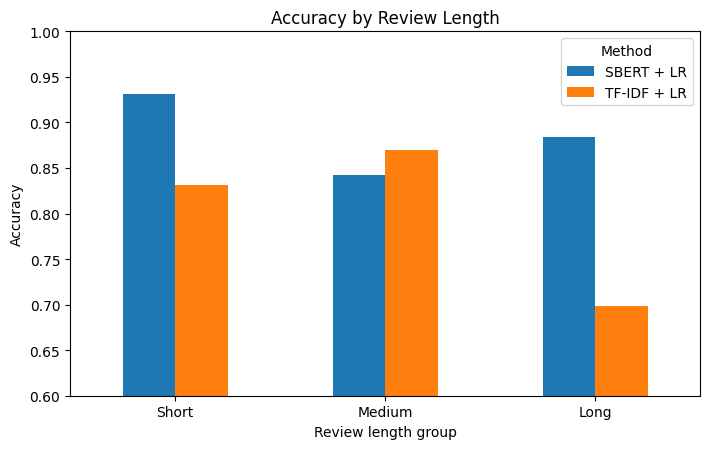

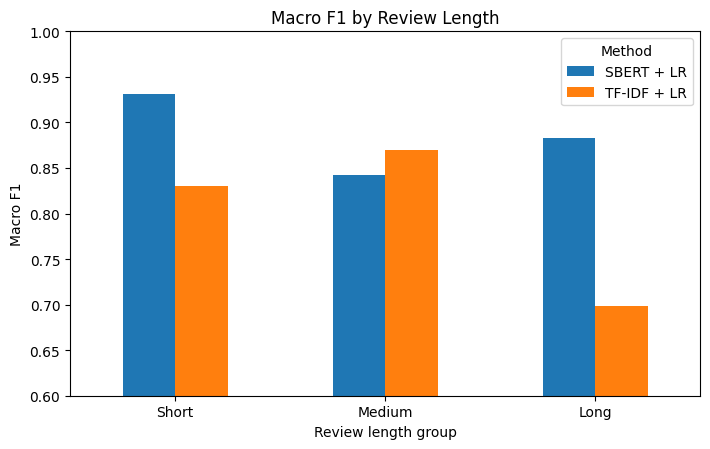

In [38]:
order = ['Short','Medium','Long']
for metric, label in [('accuracy','Accuracy'), ('macro_f1','Macro F1')]:
    pivot = (comparison[comparison['length_group'].isin(order)]
             .pivot(index='length_group', columns='model', values=metric)
             .reindex(order))
    ax = pivot.plot(kind='bar', figsize=(7.2,4.6))
    ax.set_ylim(0.6,1.0)
    ax.set_ylabel(label)
    ax.set_xlabel('Review length group')
    ax.set_title(f'{label} by Review Length')
    ax.legend(title='Method')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{metric}_by_length.png', dpi=180)
    plt.show()

## 6. Confusion matrices and disagreement patterns

In [39]:
cm_rows = []
for model_name, pred_col in [('TF-IDF + LR','tfidf_prediction'), ('SBERT + LR','sbert_prediction')]:
    for group in ['Overall','Short','Medium','Long']:
        subset = combined if group == 'Overall' else combined[combined['length_group'].eq(group)]
        cm = confusion_matrix(subset['true_label'], subset[pred_col], labels=[0,1])
        cm_rows.append({'model':model_name,'length_group':group,
                        'tn':int(cm[0,0]),'fp':int(cm[0,1]),'fn':int(cm[1,0]),'tp':int(cm[1,1])})
confusions = pd.DataFrame(cm_rows)
confusions.to_csv(OUT_DIR / 'confusion_matrices.csv', index=False)
display(confusions)

combined['outcome_pattern'] = np.select(
    [combined['tfidf_correct'] & combined['sbert_correct'],
     ~combined['tfidf_correct'] & combined['sbert_correct'],
     combined['tfidf_correct'] & ~combined['sbert_correct'],
     ~combined['tfidf_correct'] & ~combined['sbert_correct']],
    ['Both correct','SBERT only correct','TF-IDF only correct','Both wrong'], default=''
)
pattern_table = (combined.groupby(['length_group','outcome_pattern']).size()
                 .unstack(fill_value=0).reindex(['Short','Medium','Long']))
pattern_table.loc['Overall'] = combined['outcome_pattern'].value_counts()
pattern_table.to_csv(OUT_DIR / 'agreement_error_patterns.csv')
display(pattern_table)

,model,length_group,tn,fp,fn,tp
0,TF-IDF + LR,Overall,176,48,42,186
1,TF-IDF + LR,Short,61,17,10,72
2,TF-IDF + LR,Medium,61,7,12,66
3,TF-IDF + LR,Long,54,24,20,48
4,SBERT + LR,Overall,204,20,31,197
5,SBERT + LR,Short,75,3,8,74
6,SBERT + LR,Medium,62,6,17,61
7,SBERT + LR,Long,67,11,6,62


outcome_pattern,Both correct,Both wrong,SBERT only correct,TF-IDF only correct
length_group,,,,
Short,127,5,22,6
Medium,114,10,9,13
Long,95,10,34,7
Overall,336,25,65,26


In [40]:

from scipy.stats import chi2

def mcnemar_cc(tfidf_correct, sbert_correct):
    """McNemar test with continuity correction on the discordant pairs."""
    b = int((tfidf_correct & ~sbert_correct).sum())   # only TF-IDF correct
    c = int((~tfidf_correct & sbert_correct).sum())   # only SBERT correct
    if b + c == 0:
        return b, c, 0.0, 1.0
    stat = (abs(b - c) - 1) ** 2 / (b + c)
    return b, c, stat, float(chi2.sf(stat, df=1))

mcnemar_rows = []
for group in ['Overall', 'Short', 'Medium', 'Long']:
    subset = combined if group == 'Overall' else combined[combined['length_group'].eq(group)]
    b, c, stat, p = mcnemar_cc(subset['tfidf_correct'], subset['sbert_correct'])
    mcnemar_rows.append({'length_group': group, 'n': len(subset),
                         'tfidf_only_correct': b, 'sbert_only_correct': c,
                         'chi2': round(stat, 3), 'p_value': round(p, 4),
                         'significant_at_0.05': p < 0.05})
mcnemar_table = pd.DataFrame(mcnemar_rows)
mcnemar_table.to_csv(OUT_DIR / 'mcnemar_tests.csv', index=False)
display(mcnemar_table)

,length_group,n,tfidf_only_correct,sbert_only_correct,chi2,p_value,significant_at_0.05
0,Overall,452,26,65,15.868,0.0001,True
1,Short,160,6,22,8.036,0.0046,True
2,Medium,146,13,9,0.409,0.5224,False
3,Long,146,7,34,16.488,0.0000,True


In [41]:
def near_dup_key(text):
    text = re.sub(r'[^\w\s]', '', str(text).lower())
    return re.sub(r'\s+', ' ', text).strip()

train_dev_keys = set(pd.concat([train_df['text'], dev_df['text']]).map(near_dup_key))
combined['near_dup_in_train_dev'] = combined['text'].map(near_dup_key).isin(train_dev_keys)
print('Test reviews with a case/punctuation variant in train or dev:',
      int(combined['near_dup_in_train_dev'].sum()))
display(combined.loc[combined['near_dup_in_train_dev'], ['text', 'true_label', 'length_group', 'source']])

short = combined[combined['length_group'].eq('Short')]
short_clean = short[~short['near_dup_in_train_dev']]
sensitivity = pd.DataFrame([
    {'subset': name, 'n': len(s),
     'tfidf_accuracy': s['tfidf_correct'].mean(), 'sbert_accuracy': s['sbert_correct'].mean()}
    for name, s in [('Short (all)', short), ('Short (variants removed)', short_clean)]
]).round(4)
sensitivity.to_csv(OUT_DIR / 'near_duplicate_sensitivity.csv', index=False)
display(sensitivity)

Test reviews with a case/punctuation variant in train or dev: 4


,text,true_label,length_group,source
2,VERY DISAPPOINTED.,0,Short,Amazon
82,Great Product.,1,Short,Amazon
149,disappointed.,0,Short,Amazon
249,You wont regret it!,1,Short,IMDb


,subset,n,tfidf_accuracy,sbert_accuracy
0,Short (all),160,0.8312,0.9312
1,Short (variants removed),156,0.8269,0.9359


## 7. Error analysis
The project guidelines require at least three wrong predictions to be explained. The three cases below are deliberately selected to connect the errors to the research question rather than choosing random mistakes.

In [42]:
# 1) Long review: TF-IDF wrong, SBERT correct
case1 = (combined[(~combined['tfidf_correct']) & combined['sbert_correct'] & combined['length_group'].eq('Long')]
         .sort_values('word_count', ascending=False).head(1))
# 2) Medium review: TF-IDF correct, SBERT wrong
case2 = (combined[combined['tfidf_correct'] & (~combined['sbert_correct']) & combined['length_group'].eq('Medium')]
         .sort_values('word_count', ascending=False).head(1))
# 3) Both wrong, short
case3 = combined[combined['text'].eq("Don't miss it.")].head(1)
selected_errors = pd.concat([case1, case2, case3], ignore_index=True)
selected_errors['case'] = ['Long: TF-IDF wrong / SBERT correct',
                           'Medium: TF-IDF correct / SBERT wrong',
                           'Short: both models wrong']
selected_errors[['case','text','true_label','word_count','tfidf_prediction','sbert_prediction',
                 'tfidf_prob_positive','sbert_prob_positive']].to_csv(OUT_DIR/'selected_error_cases.csv', index=False)
display(selected_errors[['case','text','true_label','word_count','tfidf_prediction','sbert_prediction',
                         'tfidf_prob_positive','sbert_prob_positive']])

,case,text,true_label,word_count,tfidf_prediction,sbert_prediction,tfidf_prob_positive,sbert_prob_positive
0,Long: TF-IDF wrong / SBERT correct,"When a song could explain the emotions of the subjects better, such as when Jay Adams' unfortunate life was a subjec...",1,36,0,1,0.332219,0.725030
1,Medium: TF-IDF correct / SBERT wrong,I had absolutely no problem with this headset linking to my 8530 Blackberry Curve!,1,14,1,0,0.543172,0.291561
2,Short: both models wrong,Don't miss it.,1,3,0,0,0.158615,0.074034


### Interpretation of the selected cases
1. **Long positive review:** the positive signal is distributed across a long sentence containing many neutral words. TF-IDF predicts Negative while SBERT predicts Positive. This is consistent with the possibility that sentence-level embeddings can preserve broader semantic context when lexical evidence is spread across a longer review. This is an interpretation of this example, not proof of a causal mechanism.
2. **Medium positive review with “no problem”:** TF-IDF correctly predicts Positive while SBERT predicts Negative. The word bigram representation can preserve a local phrase such as “no problem,” so a traditional representation can still be effective for some medium-length expressions.
3. **Short review “Don’t miss it.”:** both models predict Negative although the label is Positive. The phrase contains negative surface wording but functions as a positive recommendation. With only three words, there is little additional context to resolve the idiom.

## 8. Main findings

In [43]:
wide = comparison.pivot(index='length_group', columns='model', values=['accuracy','macro_f1'])
for group in ['Overall','Short','Medium','Long']:
    a1 = wide.loc[group,('accuracy','TF-IDF + LR')]
    a2 = wide.loc[group,('accuracy','SBERT + LR')]
    f1_1 = wide.loc[group,('macro_f1','TF-IDF + LR')]
    f1_2 = wide.loc[group,('macro_f1','SBERT + LR')]
    print(f"{group:7s} | TF-IDF Acc/F1={a1:.4f}/{f1_1:.4f} | SBERT Acc/F1={a2:.4f}/{f1_2:.4f}")

print(); print('Research-question answer:')
print('- Review length is associated with meaningful changes in performance for both methods.')
print('- SBERT is significantly stronger overall and on Short and Long reviews (McNemar p < 0.01).')
print('- On Medium reviews the two methods do not differ significantly (McNemar p = 0.52).')
print('- Under the predefined Macro-F1 range measure, SBERT is more consistent across length groups.')

Overall | TF-IDF Acc/F1=0.8009/0.8008 | SBERT Acc/F1=0.8872/0.8871
Short   | TF-IDF Acc/F1=0.8313/0.8304 | SBERT Acc/F1=0.9313/0.9312
Medium  | TF-IDF Acc/F1=0.8699/0.8697 | SBERT Acc/F1=0.8425/0.8425
Long    | TF-IDF Acc/F1=0.6986/0.6981 | SBERT Acc/F1=0.8836/0.8834

Research-question answer:
- Review length is associated with meaningful changes in performance for both methods.
- SBERT is significantly stronger overall and on Short and Long reviews (McNemar p < 0.01).
- On Medium reviews the two methods do not differ significantly (McNemar p = 0.52).
- Under the predefined Macro-F1 range measure, SBERT is more consistent across length groups.


### 9. Interactive Sentiment Prediction (Try It)

This section demonstrates sentiment prediction on new English reviews using the trained TF-IDF + Logistic Regression and Sentence-BERT + Logistic Regression models.

The `try_it_both()` function accepts a review as input and returns the predicted sentiment (Positive or Negative) along with the positive-class probability for each model.

Both models are reused for inference without retraining or modifying their parameters. Input validation is also included to handle empty or invalid reviews appropriately.

In [44]:
# Interactive sentiment prediction using the trained TF-IDF and SBERT models.
# Both models perform inference without retraining.
def try_it_both(review):
    if not isinstance(review, str) or not review.strip():
        return {'message': 'Please enter a non-empty English review.'}
    cleaned = review.strip()
    tfidf_prob = float(final_model.predict_proba([cleaned])[0, list(final_model.classes_).index(1)])
    embedding = m2_encoder.encode([cleaned], convert_to_numpy=True, normalize_embeddings=True)
    sbert_prob = float(m2_classifier.predict_proba(embedding)[0, list(m2_classifier.classes_).index(1)])
    return {
        'review': cleaned,
        'TF-IDF prediction': 'Positive' if tfidf_prob >= .5 else 'Negative',
        'TF-IDF P(Positive)': round(tfidf_prob, 4),
        'Sentence-BERT prediction': 'Positive' if sbert_prob >= .5 else 'Negative',
        'Sentence-BERT P(Positive)': round(sbert_prob, 4),
    }

print(try_it_both('The service was quick and the food was excellent.'))
print(try_it_both(''))

{'review': 'The service was quick and the food was excellent.', 'TF-IDF prediction': 'Positive', 'TF-IDF P(Positive)': 0.9218, 'Sentence-BERT prediction': 'Positive', 'Sentence-BERT P(Positive)': 0.9604}
{'message': 'Please enter a non-empty English review.'}


### 10. Team-Provided Examples

Each group member contributed two original English reviews with manually assigned sentiment labels (Positive or Negative).

The examples below demonstrate how both trained models classify new text. Their predictions are compared with the intended labels for qualitative inspection.

These examples are separate from the held-out test set and are not included in the reported Accuracy or Macro F1 scores.

In [45]:
examples = [
 ("Estabraq", "Great value, it arrived early and works perfectly.", "Positive"),
 ("Estabraq", "Complete waste of money.", "Negative"),
 ("Fay", "The staff were friendly and the room was spotless, so we will definitely stay here again on our next trip.", "Positive"),
 ("Fay", "Not bad at all, I would order it again.", "Positive"),
 ("Ghadah", "I expected to love this film, but the plot dragged on and the ending left me bored and disappointed.", "Negative"),
 ("Ghadah", "Loved it.", "Positive"),
 ("Maha", "The battery died after two days and customer support never replied to any of my emails.", "Negative"),
 ("Maha", "The food was cold and the service was extremely slow.", "Negative"),
]

for who, text, truth in examples:
    result = try_it_both(text)

    print(f"\nMember: {who}")
    print(f"Review: {text}")
    print(f"Expected sentiment: {truth}")
    print(f"Review length: {len(text.split())} words")

    print(f"TF-IDF prediction: {result['TF-IDF prediction']}")
    print(f"SBERT prediction: {result['Sentence-BERT prediction']}")
    print("-" * 60)



Member: Estabraq
Review: Great value, it arrived early and works perfectly.
Expected sentiment: Positive
Review length: 8 words
TF-IDF prediction: Positive
SBERT prediction: Positive
------------------------------------------------------------

Member: Estabraq
Review: Complete waste of money.
Expected sentiment: Negative
Review length: 4 words
TF-IDF prediction: Negative
SBERT prediction: Negative
------------------------------------------------------------

Member: Fay
Review: The staff were friendly and the room was spotless, so we will definitely stay here again on our next trip.
Expected sentiment: Positive
Review length: 20 words
TF-IDF prediction: Positive
SBERT prediction: Negative
------------------------------------------------------------

Member: Fay
Review: Not bad at all, I would order it again.
Expected sentiment: Positive
Review length: 9 words
TF-IDF prediction: Negative
SBERT prediction: Positive
------------------------------------------------------------

Member: G

## References and Sources

**Dataset**

UCI Machine Learning Repository. *Sentiment Labelled Sentences*. https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences

**Pretrained Model**

Sentence-Transformers. *all-MiniLM-L6-v2*. https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2

**Related Research**

[1] Kotzias, D., Denil, M., de Freitas, N., & Smyth, P. (2015). *From Group to Individual Labels Using Deep Features*. Proceedings of ACM SIGKDD.

[2] Al-Natour, S., & Turetken, O. (2020). *A comparative assessment of sentiment analysis and star ratings for consumer reviews*. International Journal of Information Management, 54, 102132.

[3] Reimers, N., & Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks*. Proceedings of EMNLP-IJCNLP.

[4] Salton, G., & Buckley, C. (1988). *Term-weighting approaches in automatic text retrieval*. Information Processing & Management, 24(5), 513–523.

[5] Pang, B., Lee, L., & Vaithyanathan, S. (2002). *Thumbs up? Sentiment classification using machine learning techniques*. Proceedings of EMNLP.

**Implementation Libraries**

Python, pandas, NumPy, scikit-learn, SciPy, Matplotlib, Sentence-Transformers, and joblib.

The project uses public labelled data, existing software libraries, and pretrained model weights.

**AI Assistance**

Claude (Anthropic) was used to review the code and data pipeline, suggest additional analysis cells (the McNemar test and the near-duplicate check), and help draft and edit the report. All reported results were produced by running this notebook.